# Lab: Build your first image encoder–decoder

**Time:** 60–90 minutes. **Prerequisites:** Python, tensors, basic convolutions, and gradient descent.

Read [CNN-Based Encoder–Decoder Architectures for Images](../../lectures/encoder_decoder/encoder_decoder.md), especially Sections 2–7.

You will reconstruct handwritten digits using a small convolutional network. Each image is both the input and the target: this training task makes our encoder–decoder an **autoencoder**. Digit labels are not used for training.

By the end, you should be able to:
- implement an encoder, spatial latent representation, and decoder;
- trace `[N, C, H, W]` shapes through downsampling and upsampling;
- train with reconstruction MSE and inspect held-out reconstructions;
- measure latent size and explain the bottleneck trade-off.

Complete the four TODO sections. Data loading, plotting, and evaluation are provided. TODO cells intentionally raise `NotImplementedError` until you implement them. Run cells in order.

**Vansh Joshi — revised work.** This notebook follows the assigned architecture and clean-image reconstruction task. Results below come from three fresh five-epoch runs, with the prescribed 5,000/1,000 fixed MNIST subsets. The optional denoising extension is not part of these runs.


**Provenance:** Completed from the official student template with AI assistance. All reported metrics and figures were produced by the executed cells; interpretations refer to those outputs.


## 1. Set up and load data (10 minutes)
Use a Python 3 notebook kernel. If needed, uncomment the installation cell, run it once, and restart the kernel. A GPU is optional. The first dataset load needs internet access; later runs use the local cache. `ToTensor()` scales MNIST pixels to `[0, 1]`; do not apply mean/std normalization for this lab.

In [1]:
# %pip install torch torchvision matplotlib

Device: cuda
Batch: (64, 1, 28, 28) Pixel range: 0.0 1.0


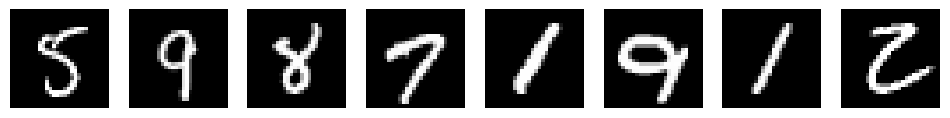

PyTorch: 2.10.0+cu128 Python: 3.13.11
Train/held-out: 5000 1000 Epochs: 5 Seed: 42


In [2]:
import os, json, platform
from pathlib import Path
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.set_num_threads(4)
torch.manual_seed(42)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
DATA_PATH = Path(os.environ.get("LAB_DATA_PATH", "data"))
OUTPUT_DIR = Path("encoder_decoder_vansh_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 64
EPOCHS = 5  # Start with 1 to check your code, then train for 5.
LATENT_CHANNELS = 8
print("Device:", device)

train_data = datasets.MNIST(DATA_PATH, train=True, download=True, transform=transforms.ToTensor())
test_data = datasets.MNIST(DATA_PATH, train=False, download=True, transform=transforms.ToTensor())
# Fixed random subsets keep the exercise small and comparisons repeatable.
g = torch.Generator().manual_seed(42)
train_data = Subset(train_data, torch.randperm(len(train_data), generator=g)[:5000].tolist())
test_data = Subset(test_data, torch.randperm(len(test_data), generator=g)[:1000].tolist())
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, generator=torch.Generator().manual_seed(42))
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
images, labels = next(iter(train_loader))
print("Batch:", tuple(images.shape), "Pixel range:", images.min().item(), images.max().item())
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, img in zip(axes, images[:8]):
    ax.imshow(img[0], cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
plt.show()
print("PyTorch:", torch.__version__, "Python:", platform.python_version())
print("Train/held-out:", len(train_data), len(test_data), "Epochs:", EPOCHS, "Seed:", 42)


## 2. Predict the shapes (10 minutes)
Before coding, fill in the blanks. Use the convolution formulas in Sections 3.1 and 5.1 of the lecture. Assume dilation 1.

| Stage | Layer | Output shape |
|---|---|---|
| Input | — | `[N, 1, 28, 28]` |
| Encoder 1 | Conv2d: 1 → 16, kernel 3, stride 2, padding 1; ReLU | `[N, 16, 14, 14]` |
| Encoder 2 | Conv2d: 16 → 32, kernel 3, stride 2, padding 1; ReLU | `[N, 32, 7, 7]` |
| Bottleneck | Conv2d: 32 → L, kernel 1 | `[N, L, 7, 7]` |
| Decoder 1 | ConvTranspose2d: L → 16, kernel 3, stride 2, padding 1, output_padding 1; ReLU | `[N, 16, 14, 14]` |
| Decoder 2 | ConvTranspose2d: 16 → 1, same spatial settings; Sigmoid | `[N, 1, 28, 28]` |

**Write your answers here:**
1. For `L=8`, input values per image = 1×28×28 = **784**; latent values = 8×7×7 = **392**; input/latent ratio = **2:1**.
2. For `L=32`, the latent contains 32×7×7 = **1,568** values, twice the 784 input values. It is **not dimensionally compressed**, despite its smaller spatial grid.
3. The final **Sigmoid** produces values in (0,1), matching the [0,1] targets from `ToTensor()`. This makes the predicted values compatible with the pixel scale.
4. With input height 7 and `output_padding=0`, H_out = (7−1)×2 − 2×1 + (3−1) + 0 + 1 = **13**, rather than 14.

The 1×1 bottleneck mixes channels at each location. It preserves the spatial grid; no flattening or linear layer is needed. The input/latent ratio counts tensor values, not file size or actual encoded bits.

## 3. Implement the network (20 minutes)
**TODO 1:** Define `self.network` in `Encoder` using the three convolutional layers in the table and ReLU after the first two. Leave the bottleneck output without an activation.

**TODO 2:** Define `self.network` in `Decoder` using the two transposed convolutions, ReLU between them, and Sigmoid at the end.

**TODO 3:** Implement `forward` in the combined model. Return `(reconstruction, z)`. Hints: use `nn.Sequential`, `nn.Conv2d`, and `nn.ConvTranspose2d`.

In [3]:
class Encoder(nn.Module):
    def __init__(self, latent_channels=8):
        super().__init__()
        # TODO 1: define self.network.
        self.network = nn.Sequential(
            nn.Conv2d(1, 16, 3, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(16, 32, 3, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(32, latent_channels, 1),
        )

    def forward(self, x):
        return self.network(x)

In [4]:
class Decoder(nn.Module):
    def __init__(self, latent_channels=8):
        super().__init__()
        # TODO 2: define self.network.
        self.network = nn.Sequential(
            nn.ConvTranspose2d(latent_channels, 16, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),
            nn.ConvTranspose2d(16, 1, 3, stride=2, padding=1, output_padding=1), nn.Sigmoid(),
        )

    def forward(self, z):
        return self.network(z)

In [5]:
class ImageEncoderDecoder(nn.Module):
    def __init__(self, latent_channels=8):
        super().__init__()
        self.encoder = Encoder(latent_channels)
        self.decoder = Decoder(latent_channels)

    def forward(self, x):
        # TODO 3: encode, decode, and return both outputs.
        z = self.encoder(x)
        return self.decoder(z), z

In [6]:
# Shape and range checks: run these before training.
model = ImageEncoderDecoder(LATENT_CHANNELS).to(device)
x = torch.rand(4, 1, 28, 28, device=device)
with torch.no_grad():
    reconstruction, z = model(x)
assert z.shape == (4, LATENT_CHANNELS, 7, 7), "Check encoder stride/padding/channels"
assert reconstruction.shape == x.shape, "Check decoder output_padding"
assert torch.isfinite(reconstruction).all(), "Output contains nonfinite values"
assert ((reconstruction >= 0) & (reconstruction <= 1)).all(), "Check output activation"
print("Input:", tuple(x.shape), "Latent:", tuple(z.shape), "Output:", tuple(reconstruction.shape))
print("Shape and range checks passed")

Input: (4, 1, 28, 28) Latent: (4, 8, 7, 7) Output: (4, 1, 28, 28)
Shape and range checks passed


## 4. Train to reconstruct (15 minutes)
**TODO 4:** Complete one training step. Clear old gradients, run the model, compute MSE against `images`, backpropagate, and update the weights. Return the loss as a Python number with `.item()`.

Both components learn together because the optimizer receives all model parameters. The provided evaluation code uses held-out images, evaluation mode, and no gradient tracking. MSE is averaged over all pixels and images; it is not classification accuracy.

In [7]:
def train_step(model, images, optimizer, criterion):
    # TODO 4: implement a reconstruction training step.
    model.train()
    optimizer.zero_grad(set_to_none=True)
    reconstruction, _ = model(images)
    loss = criterion(reconstruction, images)
    loss.backward()
    optimizer.step()
    return loss.item()

L=8, untrained held-out MSE=0.186286


Epoch 1: train MSE=0.118516, held-out MSE=0.043607


Epoch 2: train MSE=0.034413, held-out MSE=0.026151


Epoch 3: train MSE=0.017333, held-out MSE=0.010093


Epoch 4: train MSE=0.008348, held-out MSE=0.006116


Epoch 5: train MSE=0.005622, held-out MSE=0.004543


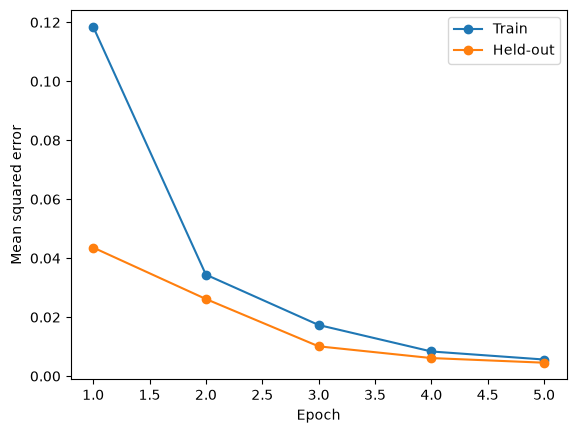

In [8]:
criterion = nn.MSELoss()

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    for images, _ in loader:
        images = images.to(device)
        reconstruction, _ = model(images)
        total_loss += criterion(reconstruction, images).item() * images.size(0)
    return total_loss / len(loader.dataset)

def train_fresh(latent_channels):
    # A separate generator gives every architecture the same shuffled minibatches.
    torch.manual_seed(42)
    train_loader.generator.manual_seed(42)
    network = ImageEncoderDecoder(latent_channels).to(device)
    optimizer = torch.optim.Adam(network.parameters(), lr=1e-3)
    initial = evaluate(network, test_loader)
    run = {"train": [], "test": []}
    print(f"L={latent_channels}, untrained held-out MSE={initial:.6f}")
    for epoch in range(EPOCHS):
        network.train()
        total_loss = 0.0
        for images, _ in train_loader:
            images = images.to(device)
            total_loss += train_step(network, images, optimizer, criterion) * images.size(0)
        run["train"].append(total_loss / len(train_loader.dataset))
        run["test"].append(evaluate(network, test_loader))
        print(f"Epoch {epoch+1}: train MSE={run['train'][-1]:.6f}, held-out MSE={run['test'][-1]:.6f}")
    return network, run, initial

model, history, initial_mse = train_fresh(LATENT_CHANNELS)
plt.plot(range(1, EPOCHS+1), history["train"], marker="o", label="Train")
plt.plot(range(1, EPOCHS+1), history["test"], marker="o", label="Held-out")
plt.xlabel("Epoch"); plt.ylabel("Mean squared error"); plt.legend()
plt.savefig(OUTPUT_DIR / "baseline_learning_curve.png", bbox_inches="tight")
plt.show()


## 5. Inspect the reconstruction and latent (10 minutes)
Look for digit identity, stroke thickness, and missing detail. A low average pixel error alone does not guarantee sharp or useful images. Feature maps are learned activations, not necessarily human-readable parts of a digit.

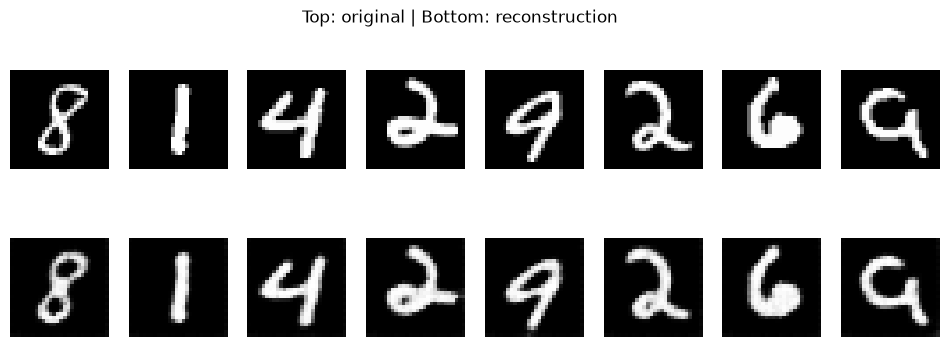

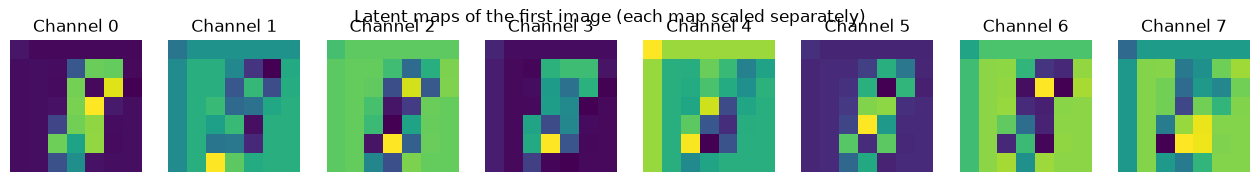

In [9]:
model.eval()
examples, _ = next(iter(test_loader))
with torch.no_grad():
    reconstructed, latents = model(examples[:8].to(device))
reconstructed, latents = reconstructed.cpu(), latents.cpu()
fig, axes = plt.subplots(2, 8, figsize=(12, 4))
for i in range(8):
    axes[0, i].imshow(examples[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[1, i].imshow(reconstructed[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[0, i].axis("off")
    axes[1, i].axis("off")
fig.suptitle("Top: original | Bottom: reconstruction")
plt.savefig(OUTPUT_DIR / "baseline_reconstructions.png", bbox_inches="tight")
plt.show()

count = min(LATENT_CHANNELS, 8)
fig, axes = plt.subplots(1, count, figsize=(2 * count, 2), squeeze=False)
for i in range(count):
    axes[0, i].imshow(latents[0, i], cmap="viridis")
    axes[0, i].set_title(f"Channel {i}")
    axes[0, i].axis("off")
fig.suptitle("Latent maps of the first image (each map scaled separately)")
plt.show()

## 6. Experiment with the bottleneck (10–15 minutes)
Run the lab with `LATENT_CHANNELS = 2`, `8`, and `32`. Change the value in the setup cell and rerun from that cell downward. Keep the data, seed, learning rate, and epoch count fixed. The training cell creates a fresh model each time. Save your observations before the next run.

| Latent channels | Values per image | Input/latent ratio | Final train MSE | Final held-out MSE | Visible differences |
|---|---|---|---|---|---|
| 2 | 98 | 8:1 | 0.013305 | 0.010941 | Digits remain recognizable, but strokes are softer; image 1 (8) has a smeared central join and image 5 (9) has a less faithful loop. |
| 8 | 392 | 2:1 | 0.005622 | 0.004543 | Sharper strokes and clearer loops than L=2, particularly the 8 and both 9 examples; some edge blur remains. |
| 32 | 1568 | 0.5:1 | 0.003834 | 0.003166 | Closest fine contours in this grid; the thin 1 and the 8 loop are better retained. Differences from L=8 are smaller than from L=2. |

This is an exploratory comparison: changing channels also changes the parameter count. Small runs may not show a consistent ranking. Since we repeatedly inspect this held-out subset, treat it as validation data rather than an untouched final benchmark.

**Discuss:**
1. Did a larger latent improve reconstruction in your runs? Support the answer with images and MSE.
2. Why is spatial downsampling alone insufficient to claim dimensional compression?
3. Why can the decoder restore image size without recovering every original detail?
4. How would a `[N, 128]` vector differ from this spatial latent?
5. Where could a skip connection carry high-resolution features? How might that weaken the bottleneck constraint?
6. Why does this exercise reconstruct existing images rather than establish a reliable random-image generator?

L=2, untrained held-out MSE=0.249615


Epoch 1: train MSE=0.180493, held-out MSE=0.090263


Epoch 2: train MSE=0.051620, held-out MSE=0.036225


Epoch 3: train MSE=0.031888, held-out MSE=0.027494


Epoch 4: train MSE=0.021719, held-out MSE=0.015138


Epoch 5: train MSE=0.013305, held-out MSE=0.010941
L=32, untrained held-out MSE=0.206002


Epoch 1: train MSE=0.119598, held-out MSE=0.031310


Epoch 2: train MSE=0.016902, held-out MSE=0.009613


Epoch 3: train MSE=0.007908, held-out MSE=0.005656


Epoch 4: train MSE=0.005134, held-out MSE=0.004051


Epoch 5: train MSE=0.003834, held-out MSE=0.003166


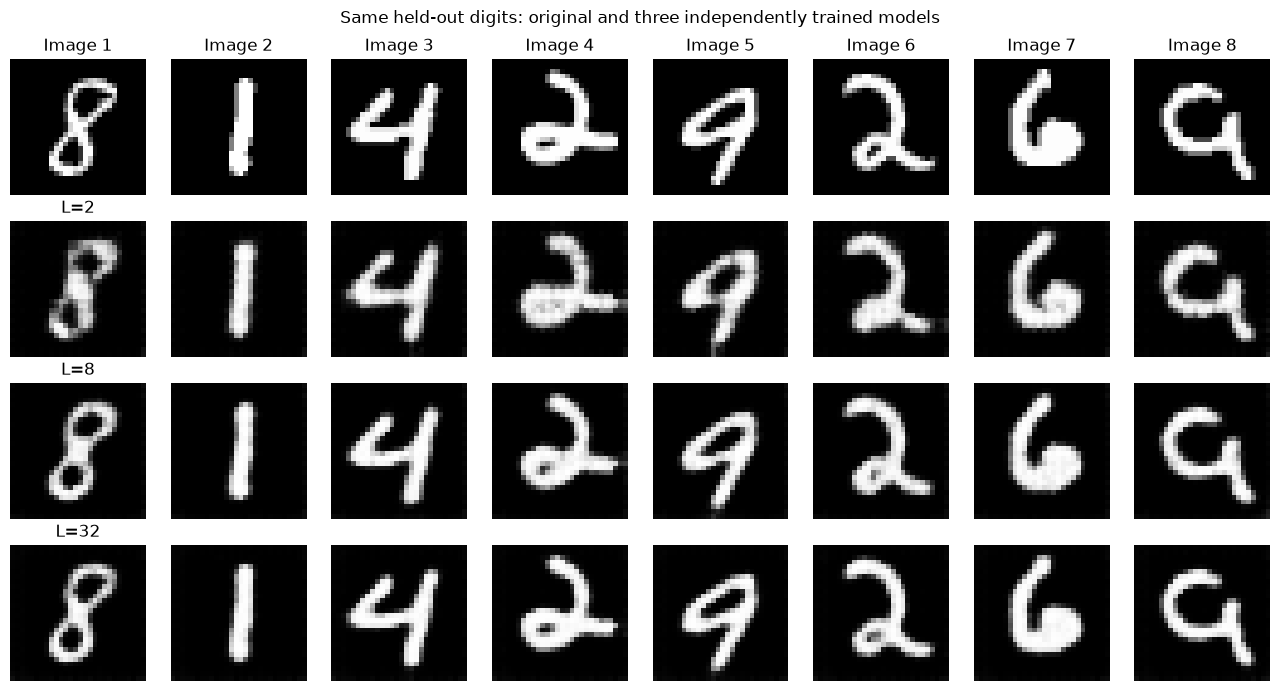

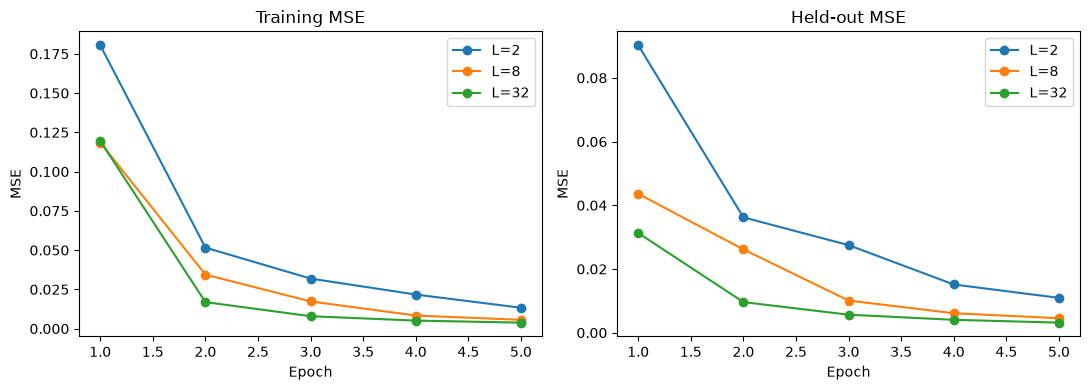

L | values | input/latent | final train MSE | final held-out MSE | parameters
2 | 98 | 8.00 | 0.013305 | 0.010941 | 5315
8 | 392 | 2.00 | 0.005622 | 0.004543 | 6377
32 | 1568 | 0.50 | 0.003834 | 0.003166 | 10625


2062

In [10]:
# The L=8 run above is a fresh model; now complete the other two fresh runs.
models = {8: model}
histories = {8: history}
initial_losses = {8: initial_mse}
for latent_channels in (2, 32):
    models[latent_channels], histories[latent_channels], initial_losses[latent_channels] = train_fresh(latent_channels)

examples, labels = next(iter(test_loader))
fig, axes = plt.subplots(4, 8, figsize=(13, 7))
for col in range(8):
    axes[0, col].imshow(examples[col, 0], cmap="gray", vmin=0, vmax=1)
    axes[0, col].set_title(f"Image {col+1}")
    axes[0, col].axis("off")
axes[0, 0].set_ylabel("Original")
results = []
for row, latent_channels in enumerate((2, 8, 32), start=1):
    network = models[latent_channels]
    network.eval()
    with torch.no_grad():
        reconstruction, _ = network(examples[:8].to(device))
    for col in range(8):
        axes[row, col].imshow(reconstruction[col, 0].cpu(), cmap="gray", vmin=0, vmax=1)
        axes[row, col].axis("off")
        if col == 0: axes[row, col].set_title(f"L={latent_channels}")
    values = latent_channels * 7 * 7
    results.append({"latent_channels":latent_channels,"values_per_image":values,
                    "input_latent_ratio":784/values,
                    "train_mse":histories[latent_channels]["train"][-1],
                    "held_out_mse":histories[latent_channels]["test"][-1],
                    "untrained_held_out_mse":initial_losses[latent_channels],
                    "parameters":sum(p.numel() for p in network.parameters())})
fig.suptitle("Same held-out digits: original and three independently trained models")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "bottleneck_comparison.png", bbox_inches="tight")
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(11,4))
for latent_channels in (2, 8, 32):
    axes[0].plot(range(1,EPOCHS+1), histories[latent_channels]["train"], marker="o", label=f"L={latent_channels}")
    axes[1].plot(range(1,EPOCHS+1), histories[latent_channels]["test"], marker="o", label=f"L={latent_channels}")
for ax, title in zip(axes, ("Training MSE", "Held-out MSE")):
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.set_ylabel("MSE"); ax.legend()
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "all_learning_curves.png", bbox_inches="tight"); plt.show()
print("L | values | input/latent | final train MSE | final held-out MSE | parameters")
for r in results:
    print(f"{r['latent_channels']} | {r['values_per_image']} | {r['input_latent_ratio']:.2f} | {r['train_mse']:.6f} | {r['held_out_mse']:.6f} | {r['parameters']}")
(OUTPUT_DIR / "results.json").write_text(json.dumps({"seed":42,"epochs":EPOCHS,"train_images":len(train_data),"held_out_images":len(test_data),"results":results,"histories":histories,"torch":torch.__version__,"device":str(device)},indent=2))


### Discussion from the completed runs

1. **Larger latents improved these runs.** Held-out MSE fell from **0.010941** (L=2) to **0.004543** (L=8) and **0.003166** (L=32). The same-image grid shows the first 8's loop and central join becoming cleaner, and the thin 1 retaining its shape. The improvement from L=8 to L=32 is visually smaller. This is one seed and five epochs; parameter counts also rise from 5,315 to 6,377 to 10,625, so the experiment does not isolate latent size from model capacity or prove a universal ranking.
2. **All dimensions must be counted.** Reducing 28×28 to 7×7 does not guarantee compression if channels increase. L=32 stores 32×7×7=1,568 values versus 784 in the input, so its input/latent ratio is 0.5:1. L=2 and L=8 store 98 and 392 values, respectively. These are tensor-value counts, not file compression ratios.
3. **Restoring shape is easier than restoring information.** The transposed convolutions learn how to upsample a representation, but the encoder's downsampling and limited bottleneck can discard distinctions between inputs. The decoder reconstructs plausible strokes from the retained information; it cannot uniquely recover details that were lost. The blurred L=2 strokes illustrate this.
4. A **[N,128] vector** has 128 values per image and no explicit 7×7 spatial arrangement. The L=8 spatial representation has 392 values, with channel features tied to grid positions. A vector decoder normally needs a learned projection and reshape before image upsampling. A 128-value vector is dimensionally smaller (784/128=6.125), but that fact alone does not establish better reconstruction.
5. A **skip connection** could pass the encoder's [N,16,14,14] activations to the decoder's 14×14 stage, for example by concatenation followed by a convolution. It can preserve higher-resolution features and improve detail, but gives the decoder information that bypasses the latent bottleneck and weakens the requirement to encode everything in z.
6. This model is trained to **reconstruct encoded examples**. MSE alone does not force encoded latents to follow a known distribution or fill latent space smoothly. A random normal z can therefore lie in a region never used in training, so reconstruction quality does not establish reliable random-image generation.

The training curves and image grid above are saved from actual execution. The held-out subset is reused for the experiment and should be treated as validation data. Each architecture was freshly initialized with seed 42, Adam 0.001, batch size 64 and five epochs, using identical shuffled index orders and the prescribed 5,000/1,000 subsets.


## Optional extension: denoising
Keep the architecture and start with a fresh model and optimizer. Add noise to the training **input**, while retaining the clean image as the **target**:

```python
noisy = (images + 0.3 * torch.randn_like(images)).clamp(0, 1)
reconstruction, _ = model(noisy)
loss = criterion(reconstruction, images)
```

Update both training and evaluation to use noisy inputs and clean targets. For evaluation, generate one fixed set of noisy held-out images and reuse it. Compare noisy-input MSE with denoised-output MSE against the clean images, and plot clean/noisy/reconstructed rows. Merely feeding noise to a reconstruction-trained model is not the same as training a denoiser.

An alternative extension is to replace each transposed convolution with 2× bilinear upsampling (`align_corners=False`) followed by a 3×3 convolution with padding 1. Keep the intermediate ReLU and final Sigmoid and check shapes before retraining.

## Submission and assessment
Submit the completed notebook with:
- all four TODOs implemented and shape checks passing (**4 marks**);
- your completed shape table and latent-size calculations (**2 marks**);
- training curves and original/reconstructed images (**2 marks**);
- the three-run experiment table and evidence-based discussion (**2 marks**).

Expected behavior: reconstruction error should generally decrease and reconstructed digits should become recognizable, though some strokes may remain blurred. No fixed MSE threshold is required. If training fails, check the target, output range, gradient update, and tensor shapes before increasing epochs.